Gráfico salvo em: CM_usuarios_vs_tempo_resposta.png


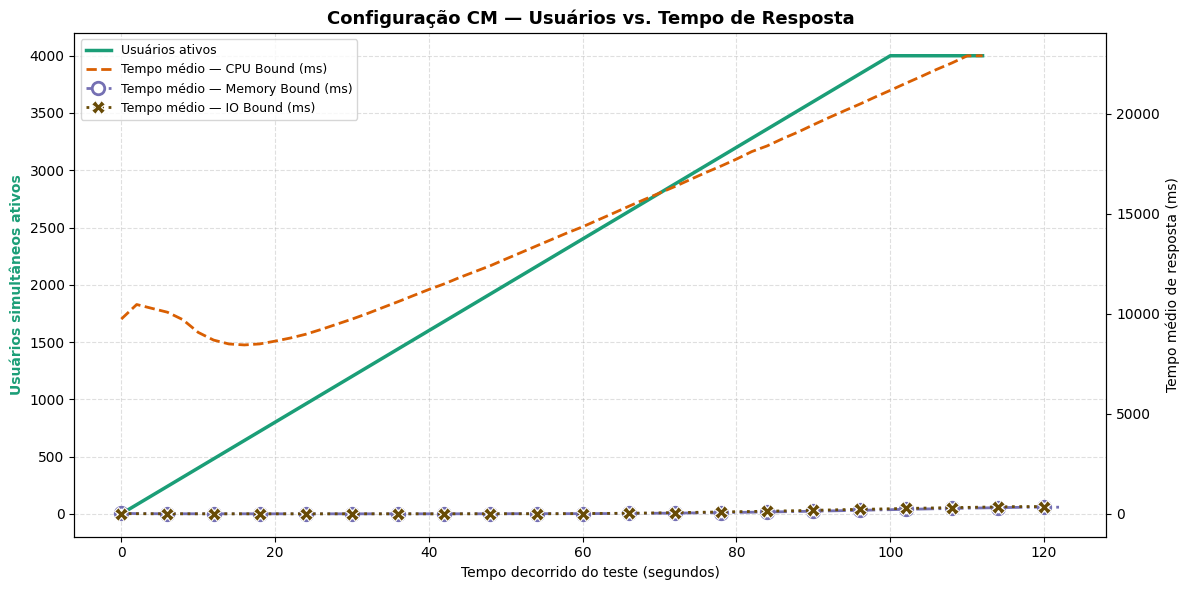

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Escolher a configuração do experimento
configuracao = "CM"

# 2. Ler os logs das três aplicações
dados = {}

for aplicacao in ["cpu_bound", "memory_bound", "io_bound"]:
    arquivo_log = f"{configuracao}/{configuracao}_{aplicacao}.log"
    dados_locust = []

    with open(arquivo_log, "r") as f:
        conteudo_log = f.read().split("Response time percentiles")[0]

    for linha in conteudo_log.strip().split("\n"):
        if linha.strip().startswith("GET"):
            partes = [p for p in linha.strip().split() if p != "|"]

            dados_locust.append({
                "media_ms": float(partes[4]),
                "mediana_ms": float(partes[7]),
            })

    df = pd.DataFrame(dados_locust)

    # 3. Calcular tempo decorrido e usuários ativos
    df["intervalo"] = range(len(df))
    df["tempo_decorrido_seg"] = df["intervalo"] * 2.0
    df["usuarios_ativos"] = np.minimum(
        4000, df["tempo_decorrido_seg"] * 40
    )

    dados[aplicacao] = df

# 4. Configurar o gráfico
fig, ax = plt.subplots(figsize=(12, 6))
ax_direito = ax.twinx()

cor1 = "#1b9e77"
cor2 = "#d95f02"
cor3 = "#7570b3"
cor4 = "#684b06"

# Usuários ativos
linha1 = ax.plot(
    dados["cpu_bound"]["tempo_decorrido_seg"],
    dados["cpu_bound"]["usuarios_ativos"],
    color=cor1,
    linewidth=2.5,
    label="Usuários ativos",
    zorder=2
)

# Tempo médio — CPU Bound
linha2 = ax_direito.plot(
    dados["cpu_bound"]["tempo_decorrido_seg"],
    dados["cpu_bound"]["media_ms"],
    color=cor2,
    linewidth=2,
    linestyle="--",
    label="Tempo médio — CPU Bound (ms)",
    zorder=2
)

# Tempo médio — Memory Bound
linha3 = ax_direito.plot(
    dados["memory_bound"]["tempo_decorrido_seg"],
    dados["memory_bound"]["media_ms"],
    color=cor3,
    linewidth=2,
    linestyle="-.",
    marker="o",
    markersize=9,
    markerfacecolor="white",
    markeredgewidth=2,
    markevery=3,
    label="Tempo médio — Memory Bound (ms)",
    zorder=3
)

# Tempo médio — IO Bound
# Desenhado por último, com marcadores em X grandes
linha4 = ax_direito.plot(
    dados["io_bound"]["tempo_decorrido_seg"],
    dados["io_bound"]["media_ms"],
    color=cor4,
    linewidth=2,
    linestyle=":",
    marker="X",
    markersize=10,
    markerfacecolor=cor4,
    markeredgecolor="white",
    markeredgewidth=0.8,
    markevery=3,
    label="Tempo médio — IO Bound (ms)",
    zorder=4
)

# 5. Personalizar o gráfico
ax.set_title(
    f"Configuração {configuracao} — Usuários vs. Tempo de Resposta",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Tempo decorrido do teste (segundos)")
ax.set_ylabel(
    "Usuários simultâneos ativos",
    color=cor1,
    fontweight="bold"
)
ax_direito.set_ylabel("Tempo médio de resposta (ms)")

# Combinar as legendas
linhas = linha1 + linha2 + linha3 + linha4
rotulos = [linha.get_label() for linha in linhas]

ax.legend(
    linhas,
    rotulos,
    loc="upper left",
    fontsize=9
)

ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

# 6. Salvar o gráfico
arquivo_saida = f"{configuracao}_usuarios_vs_tempo_resposta.png"
plt.savefig(arquivo_saida, dpi=300, bbox_inches="tight")

print(f"Gráfico salvo em: {arquivo_saida}")
plt.show()

In [9]:
print(dados.keys())

dict_keys(['cpu_bound', 'memory_bound', 'io_bound'])


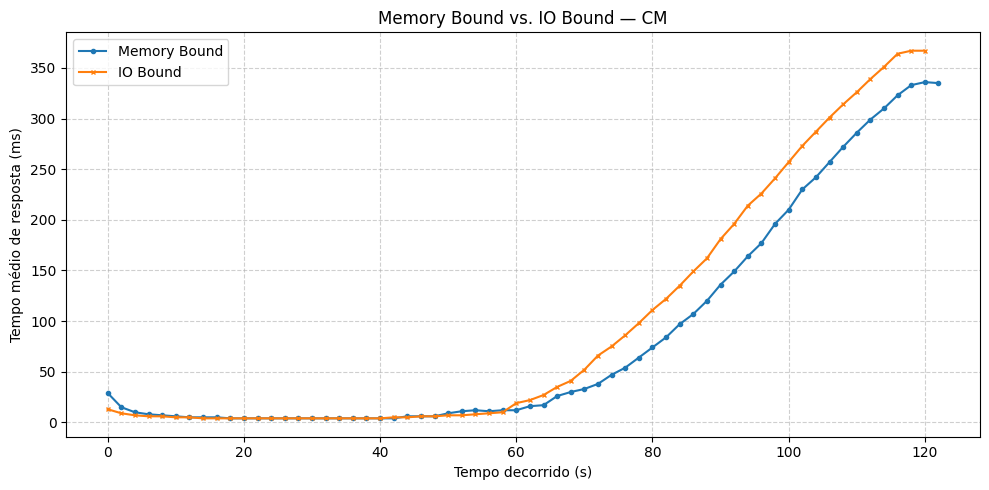

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    dados['memory_bound']['tempo_decorrido_seg'],
    dados['memory_bound']['media_ms'],
    label='Memory Bound',
    marker='o',
    markersize=3
)

plt.plot(
    dados['io_bound']['tempo_decorrido_seg'],
    dados['io_bound']['media_ms'],
    label='IO Bound',
    marker='x',
    markersize=3
)

plt.xlabel('Tempo decorrido (s)')
plt.ylabel('Tempo médio de resposta (ms)')
plt.title(f'Memory Bound vs. IO Bound — {configuracao}')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Gráfico salvo em: comparacao_cpu_bound_C1_C2_C3_C4.png


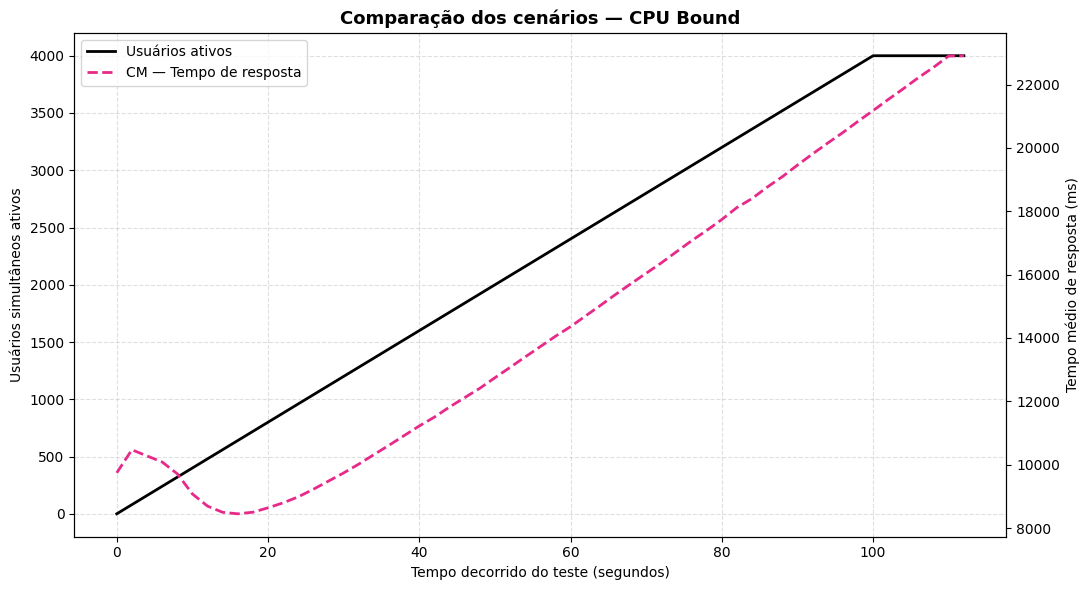

Gráfico salvo em: comparacao_memory_bound_C1_C2_C3_C4.png


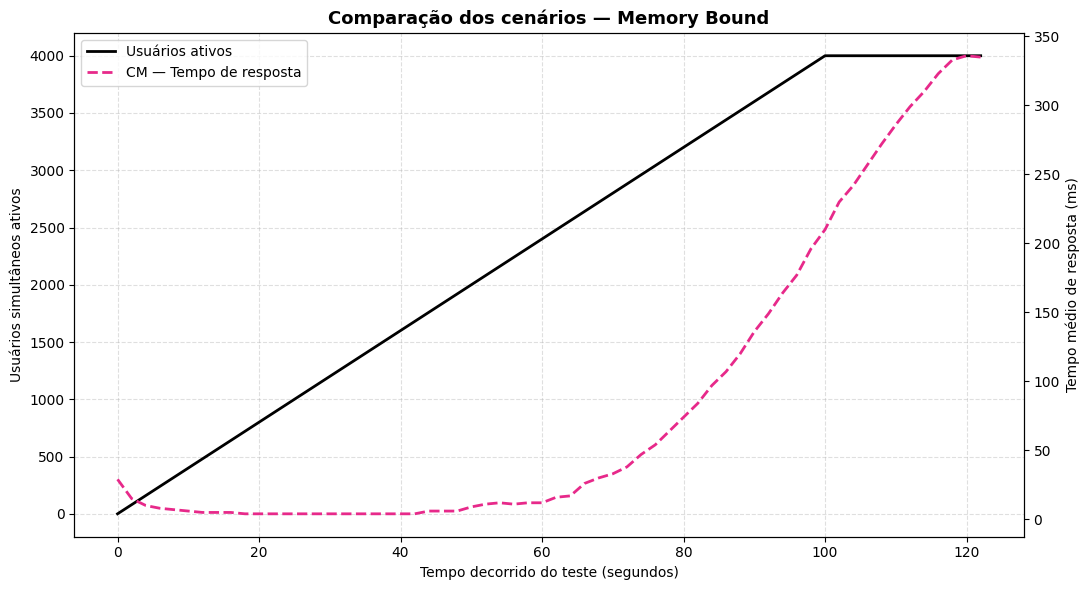

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Configurações do experimento
configuracoes = ["CM"]

aplicacoes = {
    "cpu_bound": "CPU Bound",
    "memory_bound": "Memory Bound"
}

# 2. Ler os logs das aplicações em todos os cenários
dados = {}

for aplicacao in aplicacoes:
    dados[aplicacao] = {}

    for configuracao in configuracoes:
        arquivo_log = f"{configuracao}/{configuracao}_{aplicacao}.log"
        dados_locust = []

        with open(arquivo_log, "r") as f:
            conteudo_log = f.read().split(
                "Response time percentiles"
            )[0]

        for linha in conteudo_log.strip().split("\n"):
            if linha.strip().startswith("GET"):
                partes = [
                    p for p in linha.strip().split() if p != "|"
                ]

                dados_locust.append({
                    "media_ms": float(partes[4]),
                    "mediana_ms": float(partes[7]),
                })

        df = pd.DataFrame(dados_locust)

        # 3. Calcular tempo decorrido e usuários ativos
        df["intervalo"] = range(len(df))
        df["tempo_decorrido_seg"] = df["intervalo"] * 2.0
        df["usuarios_ativos"] = np.minimum(
            4000, df["tempo_decorrido_seg"] * 40
        )

        dados[aplicacao][configuracao] = df

# 4. Cores dos cenários
cores = {
    "C1": "#1b9e77",
    "C2": "#d95f02",
    "C3": "#7570b3",
    "C4": "#e7298a",
    "CM": "#e7298a"
}

# 5. Gerar um gráfico para cada aplicação
for aplicacao, nome_aplicacao in aplicacoes.items():

    fig, ax = plt.subplots(figsize=(11, 6))
    ax_direito = ax.twinx()

    # Usuários ativos: uma única curva compartilhada
    df_base = dados[aplicacao]["CM"]

    linha_usuarios, = ax.plot(
        df_base["tempo_decorrido_seg"],
        df_base["usuarios_ativos"],
        color="black",
        linewidth=2,
        label="Usuários ativos"
    )

    linhas = [linha_usuarios]

    # Tempo médio de resposta: uma curva por cenário
    for configuracao in configuracoes:
        df = dados[aplicacao][configuracao]

        linha, = ax_direito.plot(
            df["tempo_decorrido_seg"],
            df["media_ms"],
            color=cores[configuracao],
            linewidth=2,
            linestyle="--",
            label=f"{configuracao} — Tempo de resposta"
        )

        linhas.append(linha)

    # 6. Formatação do gráfico
    ax.set_title(
        f"Comparação dos cenários — {nome_aplicacao}",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Tempo decorrido do teste (segundos)")
    ax.set_ylabel("Usuários simultâneos ativos")
    ax_direito.set_ylabel("Tempo médio de resposta (ms)")

    ax.legend(
        linhas,
        [linha.get_label() for linha in linhas],
        loc="upper left"
    )

    ax.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()

    # 7. Salvar e exibir
    arquivo_saida = (
        f"comparacao_{aplicacao}_C1_C2_C3_C4.png"
    )

    plt.savefig(arquivo_saida, dpi=300)
    print(f"Gráfico salvo em: {arquivo_saida}")

    plt.show()

Dados insuficientes: CM/CM_cpu_bound_vmstat.txt
Dados insuficientes: CM/CM_memory_bound_vmstat.txt
Gráfico salvo em: comparacao_cpu_util_pct_cpu_bound.png


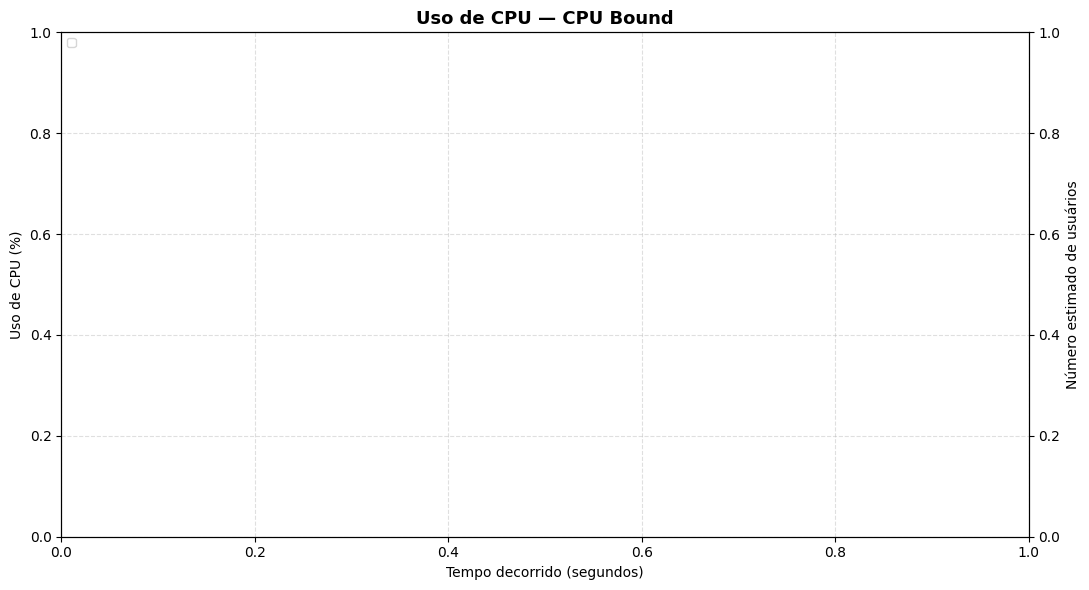

Gráfico salvo em: comparacao_memoria_usada_mb_cpu_bound.png


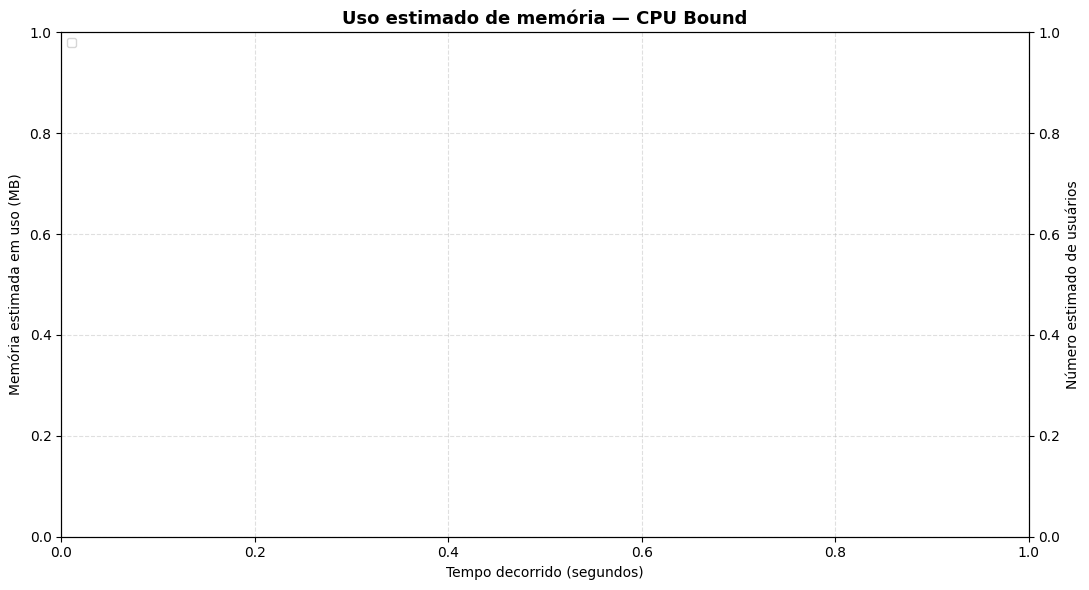

Gráfico salvo em: comparacao_cpu_util_pct_memory_bound.png


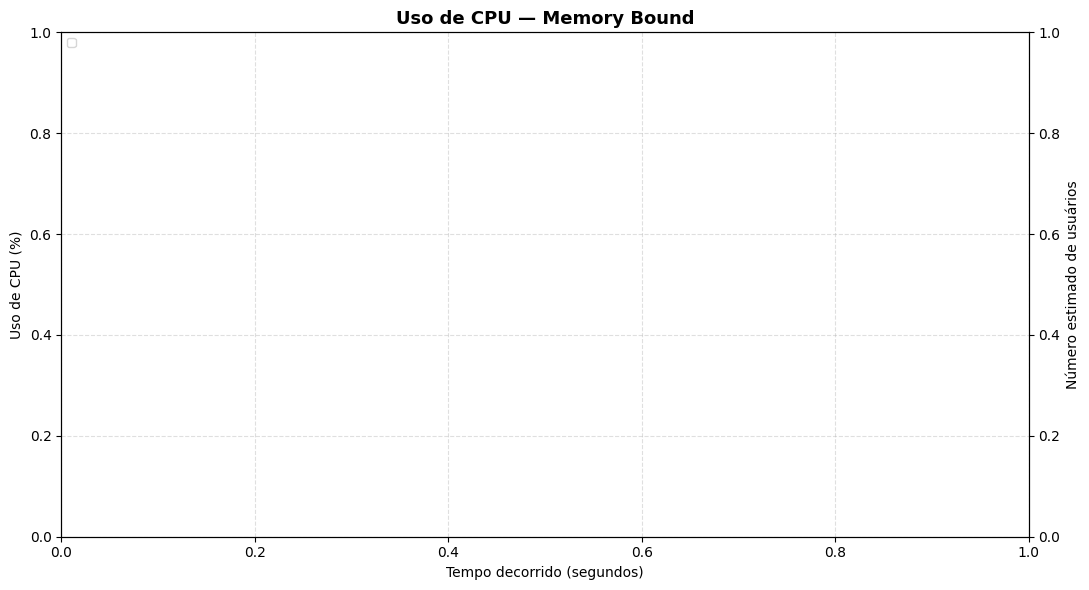

Gráfico salvo em: comparacao_memoria_usada_mb_memory_bound.png


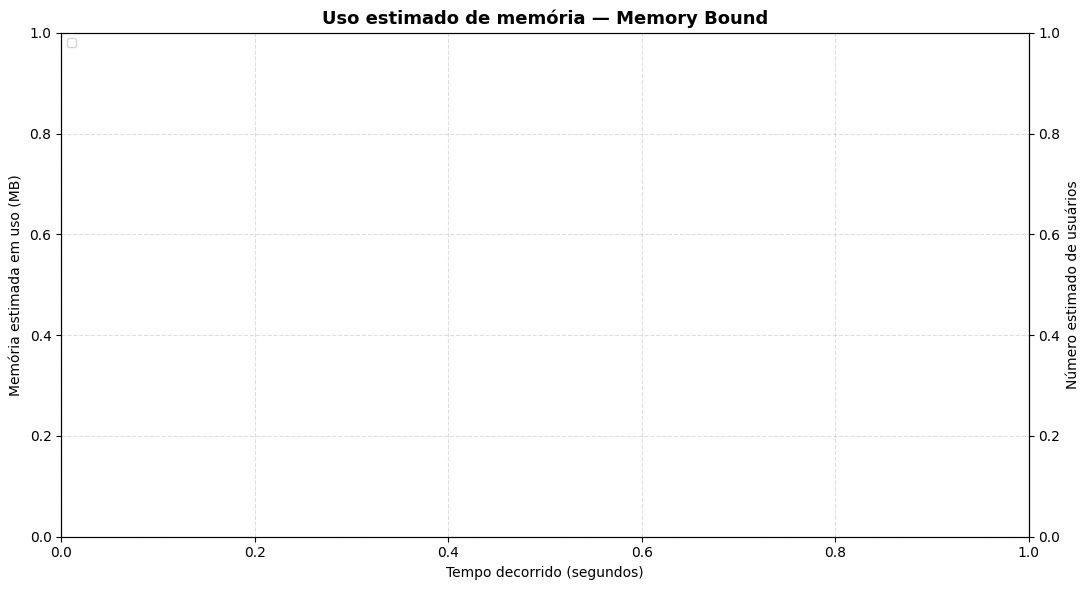

In [17]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Configurações
# configuracoes = ["C1", "C2", "C3", "C4", "CM"]
configuracoes = ["CM"]
aplicacoes = {
    "cpu_bound": "CPU Bound",
    "memory_bound": "Memory Bound"
}

RAM_MB = {
    "C1": 1024,
    "C2": 2048,
    "C3": 1024,
    "C4": 2048,
    "CM": 1024 * 16
}

colunas = [
    "r", "b", "swpd", "free", "buff", "cache",
    "si", "so", "bi", "bo", "in", "cs",
    "us", "sy", "id", "wa", "st", "data", "hora"
]

# 2. Ler os dados
dados = {}

for aplicacao in aplicacoes:
    dados[aplicacao] = {}

    for configuracao in configuracoes:
        arquivo = (
            Path(configuracao)
            / f"{configuracao}_{aplicacao}_vmstat.txt"
        )

        linhas_validas = []

        with open(arquivo, "r") as f:
            for linha in f:
                valores = linha.split()

                if len(valores) != 19:
                    continue

                try:
                    [float(v) for v in valores[:17]]
                    linhas_validas.append(valores)
                except ValueError:
                    continue

        if len(linhas_validas) < 2:
            print(f"Dados insuficientes: {arquivo}")
            continue

        # Descartar a primeira amostra
        df = pd.DataFrame(
            linhas_validas,
            columns=colunas
        ).iloc[1:].copy()

        for coluna in colunas[:17]:
            df[coluna] = pd.to_numeric(
                df[coluna], errors="coerce"
            )

        # Tempo e métricas
        df["tempo_seg"] = range(len(df))
        df["cpu_util_pct"] = 100 - df["id"]

        df["memoria_usada_mb"] = (
            RAM_MB[configuracao] - df["free"] / 1024
        )

        # Perfil estimado de usuários:
        # aumento de 40 usuários por segundo, até 4000
        df["usuarios"] = (
            df["tempo_seg"] * 40
        ).clip(upper=4000)

        dados[aplicacao][configuracao] = df

# 3. Cores
cores = {
    # "C1": "#1b9e77",
    # "C2": "#d95f02",
    # "C3": "#7570b3",
    # "C4": "#e7298a",
    "CM": "#e7298a",
}

# 4. Gerar os quatro gráficos
for aplicacao, nome_aplicacao in aplicacoes.items():

    for metrica, rotulo, titulo in [
        ("cpu_util_pct", "Uso de CPU (%)", "Uso de CPU"),
        (
            "memoria_usada_mb",
            "Memória estimada em uso (MB)",
            "Uso estimado de memória"
        )
    ]:
        fig, ax = plt.subplots(figsize=(11, 6))
        ax_direito = ax.twinx()

        linhas = []

        # Métrica de recurso para cada cenário
        for configuracao in configuracoes:
            if configuracao not in dados[aplicacao]:
                continue

            df = dados[aplicacao][configuracao]

            linha, = ax.plot(
                df["tempo_seg"],
                df[metrica],
                color=cores[configuracao],
                linewidth=2,
                label=f"{configuracao} — {rotulo}"
            )
            linhas.append(linha)

        # Usuários: desenhar uma única curva
        # pois o perfil de carga é igual nos cenários
        df_base = dados[aplicacao].get("C1")

        if df_base is not None:
            linha_usuarios, = ax_direito.plot(
                df_base["tempo_seg"],
                df_base["usuarios"],
                color="black",
                linestyle="--",
                linewidth=2,
                label="Usuários estimados"
            )
            linhas.append(linha_usuarios)

        ax.set_title(
            f"{titulo} — {nome_aplicacao}",
            fontsize=13,
            fontweight="bold"
        )

        ax.set_xlabel("Tempo decorrido (segundos)")
        ax.set_ylabel(rotulo)
        ax_direito.set_ylabel("Número estimado de usuários")

        ax.legend(
            linhas,
            [linha.get_label() for linha in linhas],
            loc="upper left",
            fontsize=8
        )

        ax.grid(True, linestyle="--", alpha=0.4)
        plt.tight_layout()

        arquivo_saida = (
            f"comparacao_{metrica}_{aplicacao}.png"
        )
        plt.savefig(arquivo_saida, dpi=300)
        print(f"Gráfico salvo em: {arquivo_saida}")

        plt.show()


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Configurações
configuracoes = ["CM"]

aplicacoes = {
    "cpu_bound": "CPU Bound",
    "memory_bound": "Memory Bound"
}

RAM_MB = {
    "C1": 1024,
    "C2": 2048,
    "C3": 1024,
    "C4": 2048,
    "CM": 1024 * 16
}

colunas = [
    "r", "b", "swpd", "free", "buff", "cache",
    "si", "so", "bi", "bo", "in", "cs",
    "us", "sy", "id", "wa", "st", "data", "hora"
]

cores = {
    "C1": "#1b9e77",
    "C2": "#d95f02",
    "C3": "#7570b3",
    "C4": "#e7298a",
    "CM": "#e7298a",
}

# 2. Ler os dados
dados = {}

for aplicacao, nome_aplicacao in aplicacoes.items():
    dados[aplicacao] = {}

    for configuracao in configuracoes:
        arquivo = (
            Path(configuracao)
            / f"{configuracao}_{aplicacao}_vmstat.txt"
        )

        print(f"\nLendo arquivo: {arquivo}")

        if not arquivo.exists():
            print(f"ERRO: arquivo não encontrado: {arquivo}")
            continue

        linhas_validas = []

        with open(arquivo, "r") as f:
            for linha in f:
                valores = linha.split()

                if len(valores) != 19:
                    continue

                try:
                    [float(v) for v in valores[:17]]
                    linhas_validas.append(valores)
                except ValueError:
                    continue

        print(f"Linhas válidas encontradas: {len(linhas_validas)}")

        if len(linhas_validas) < 2:
            print(f"ERRO: dados insuficientes em {arquivo}")
            continue

        # Criar DataFrame e descartar a primeira amostra
        df = pd.DataFrame(
            linhas_validas,
            columns=colunas
        ).iloc[1:].copy()

        for coluna in colunas[:17]:
            df[coluna] = pd.to_numeric(
                df[coluna], errors="coerce"
            )

        # Remover amostras sem dados válidos nas métricas necessárias
        df = df.dropna(subset=["id", "free"]).reset_index(drop=True)

        if df.empty:
            print(f"ERRO: nenhuma amostra numérica válida em {arquivo}")
            continue

        # 3. Calcular métricas
        # Cada amostra do vmstat corresponde aproximadamente a 1 segundo
        df["tempo_seg"] = range(len(df))

        df["cpu_util_pct"] = 100 - df["id"]

        df["memoria_usada_mb"] = (
            RAM_MB[configuracao] - df["free"] / 1024
        )

        # Perfil estimado de usuários:
        # aumento de 40 usuários por segundo, até 4000
        df["usuarios"] = (
            df["tempo_seg"] * 40
        ).clip(upper=4000)

        dados[aplicacao][configuracao] = df

        print(f"Amostras utilizadas: {len(df)}")
        print(f"CPU média: {df['cpu_util_pct'].mean():.2f}%")
        print(
            "Memória estimada média: "
            f"{df['memoria_usada_mb'].mean():.2f} MB"
        )

# 4. Gerar os gráficos
for aplicacao, nome_aplicacao in aplicacoes.items():

    for metrica, rotulo, titulo in [
        ("cpu_util_pct", "Uso de CPU (%)", "Uso de CPU"),
        (
            "memoria_usada_mb",
            "Memória estimada em uso (MB)",
            "Uso estimado de memória"
        )
    ]:
        fig, ax = plt.subplots(figsize=(11, 6))
        ax_direito = ax.twinx()

        linhas = []

        # Métrica de recurso para cada cenário
        for configuracao in configuracoes:
            df = dados[aplicacao].get(configuracao)

            if df is None or df.empty:
                continue

            linha, = ax.plot(
                df["tempo_seg"],
                df[metrica],
                color=cores.get(configuracao, "blue"),
                linewidth=2,
                label=f"{configuracao} — {rotulo}"
            )

            linhas.append(linha)

        # Usuários: utilizar o primeiro cenário disponível
        df_base = next(
            (
                dados[aplicacao][c]
                for c in configuracoes
                if c in dados[aplicacao]
            ),
            None
        )

        if df_base is not None:
            linha_usuarios, = ax_direito.plot(
                df_base["tempo_seg"],
                df_base["usuarios"],
                color="black",
                linestyle="--",
                linewidth=2,
                label="Usuários estimados"
            )

            linhas.append(linha_usuarios)

        if not linhas:
            print(
                f"\nNenhum dado para gerar gráfico: "
                f"{nome_aplicacao} — {titulo}"
            )
            plt.close(fig)
            continue

        ax.set_title(
            f"{titulo} — {nome_aplicacao}",
            fontsize=13,
            fontweight="bold"
        )

        ax.set_xlabel("Tempo decorrido (segundos)")
        ax.set_ylabel(rotulo)
        ax_direito.set_ylabel("Número estimado de usuários")

        ax.legend(
            linhas,
            [linha.get_label() for linha in linhas],
            loc="upper left",
            fontsize=8
        )

        ax.grid(True, linestyle="--", alpha=0.4)
        plt.tight_layout()

        arquivo_saida = (
            f"comparacao_{metrica}_{aplicacao}.png"
        )

        plt.savefig(arquivo_saida, dpi=300)
        print(f"Gráfico salvo em: {arquivo_saida}")

        plt.show()



Lendo arquivo: CM/CM_cpu_bound_vmstat.txt
Linhas válidas encontradas: 0
ERRO: dados insuficientes em CM/CM_cpu_bound_vmstat.txt

Lendo arquivo: CM/CM_memory_bound_vmstat.txt
Linhas válidas encontradas: 0
ERRO: dados insuficientes em CM/CM_memory_bound_vmstat.txt

Nenhum dado para gerar gráfico: CPU Bound — Uso de CPU

Nenhum dado para gerar gráfico: CPU Bound — Uso estimado de memória

Nenhum dado para gerar gráfico: Memory Bound — Uso de CPU

Nenhum dado para gerar gráfico: Memory Bound — Uso estimado de memória



Lendo: CM/CM_cpu_bound_vmstat.txt
Primeiras linhas do arquivo:
'procs -----------memory---------- ---swap-- -----io---- -system-- -------cpu------- -----timestamp-----'
' r  b   swpd   free   buff  cache   si   so    bi    bo   in   cs us sy id wa st gu                 -03'
'66  0 1944404 899604   2856 3336804    5  206  2059  2120 35828   91  8  4 88  0  0  0 2026-10-13 20:25:56'
'102  1 1944384 916816   2856 3340332   20    0    88   216 27352 29258 98  2  0  0  0  0 2026-10-13 20:25:57'
'158  0 1944364 891740   2856 3349388   20    0  6692   228 27205 29452 98  2  0  0  0  0 2026-10-13 20:25:58'
Amostras utilizadas: 123
CPU média: 99.91%
Memória estimada média: 16075.98 MB

Lendo: CM/CM_memory_bound_vmstat.txt
Primeiras linhas do arquivo:
'procs -----------memory---------- ---swap-- -----io---- -system-- -------cpu------- -----timestamp-----'
' r  b   swpd   free   buff  cache   si   so    bi    bo   in   cs us sy id wa st gu                 -03'
' 3  0 2412256 1031624   2856 36664

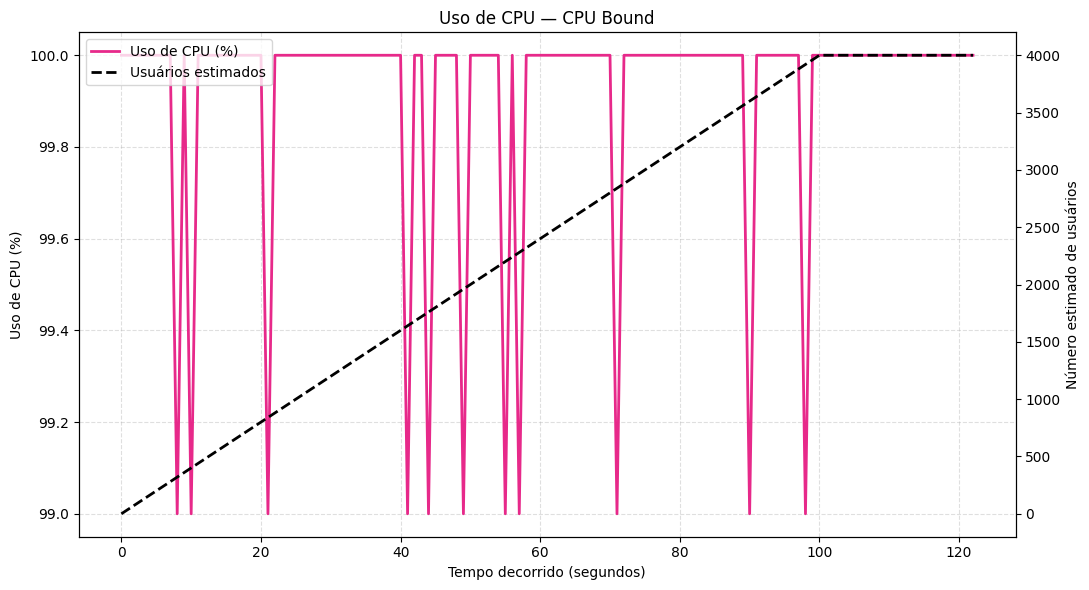

Gráfico salvo: comparacao_memoria_usada_mb_cpu_bound.png


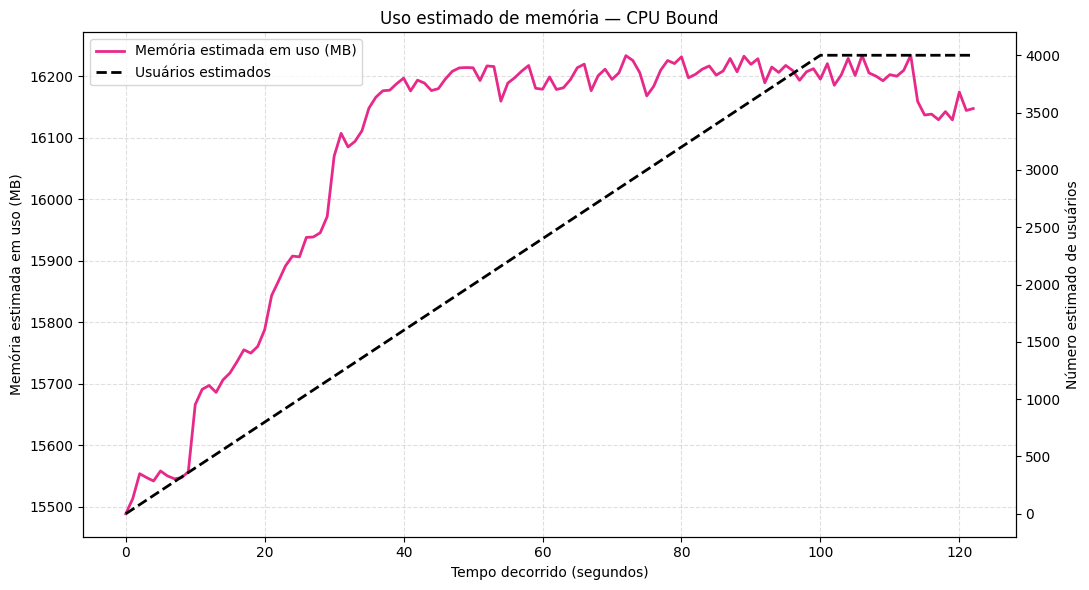

Gráfico salvo: comparacao_cpu_util_pct_memory_bound.png


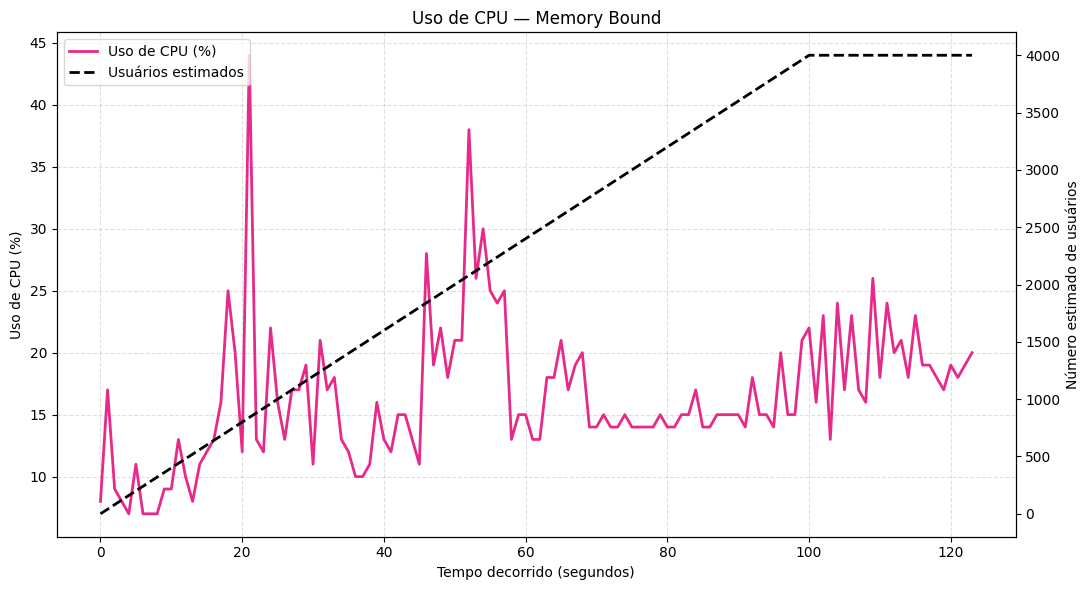

Gráfico salvo: comparacao_memoria_usada_mb_memory_bound.png


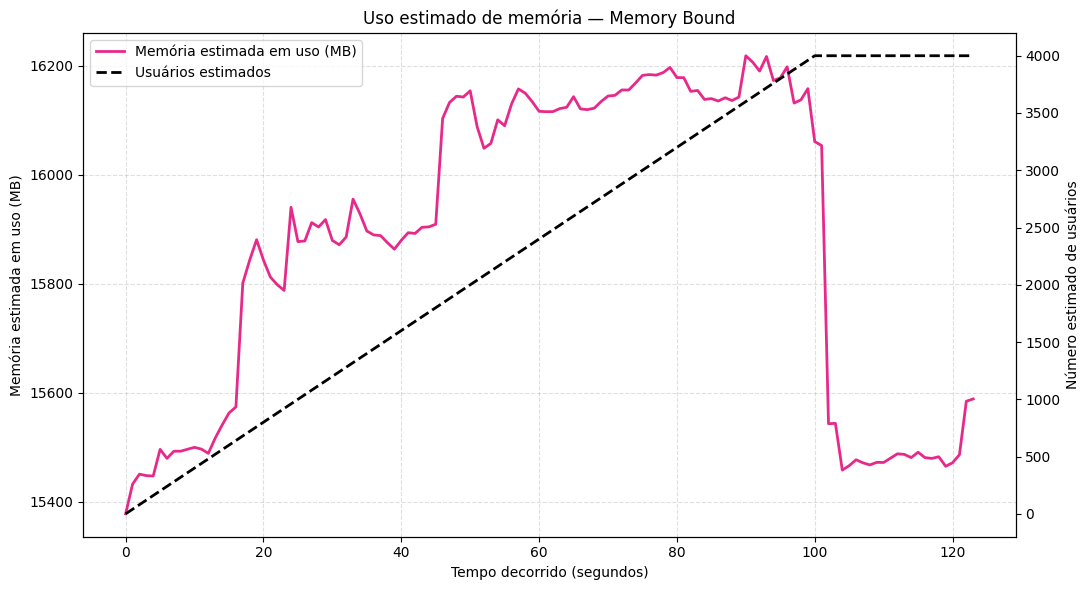

Gráfico salvo: comparacao_cpu_util_pct_io_bound.png


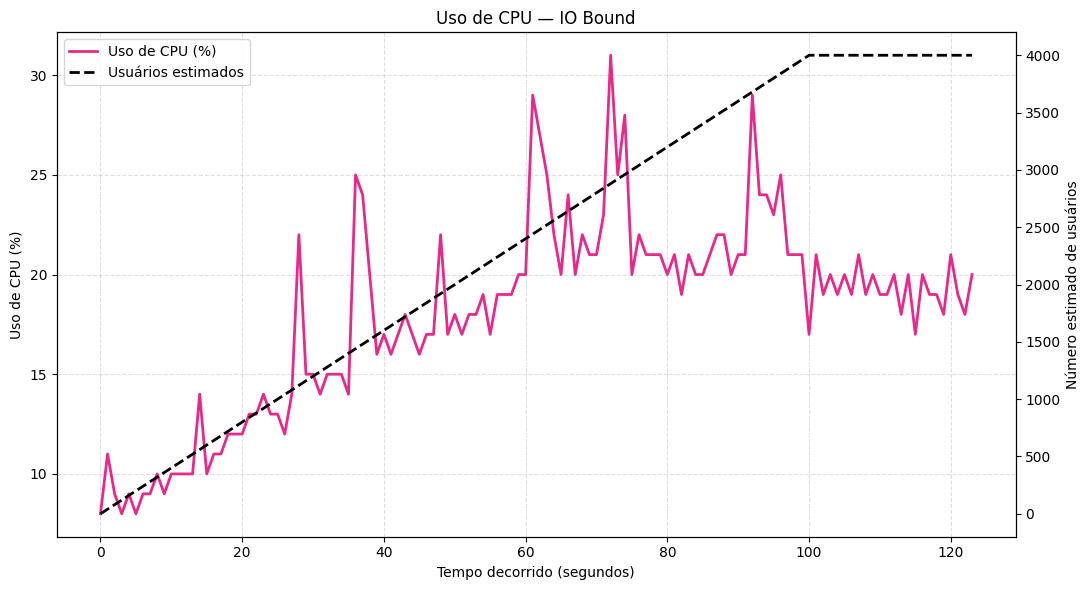

Gráfico salvo: comparacao_memoria_usada_mb_io_bound.png


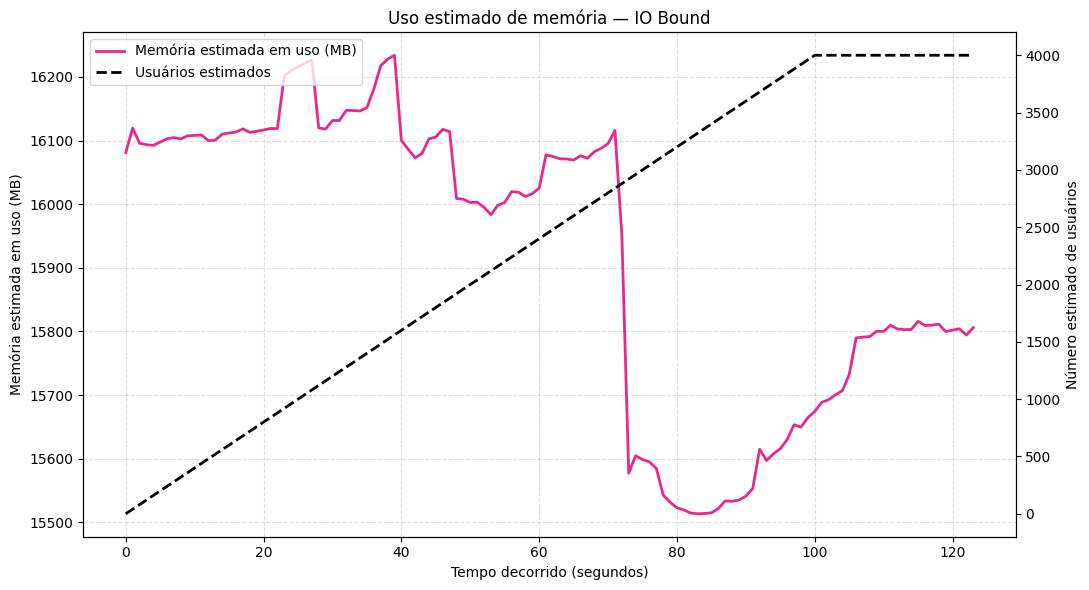

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Configuração: somente CM
CONFIGURACAO = "CM"
RAM_MB = 16 * 1024

APLICACOES = {
    "cpu_bound": "CPU Bound",
    "memory_bound": "Memory Bound",
    "io_bound": "IO Bound"
}

COR = "#e7298a"

# Colunas padrão do vmstat
COLUNAS = [
    "r", "b", "swpd", "free", "buff", "cache",
    "si", "so", "bi", "bo", "in", "cs",
    "us", "sy", "id", "wa", "st"
]

# 2. Ler os dados
dados = {}

for aplicacao, nome_aplicacao in APLICACOES.items():

    arquivo = (
        Path(CONFIGURACAO)
        / f"{CONFIGURACAO}_{aplicacao}_vmstat.txt"
    )

    print(f"\nLendo: {arquivo}")

    if not arquivo.exists():
        print("ERRO: arquivo não encontrado.")
        continue

    linhas = arquivo.read_text().splitlines()

    # Mostrar as primeiras linhas para diagnóstico
    print("Primeiras linhas do arquivo:")
    for linha in linhas[:5]:
        print(repr(linha))

    registros = []

    for linha in linhas:
        valores = linha.split()

        if not valores:
            continue

        try:
            numericos = [float(v) for v in valores[:17]]
        except ValueError:
            continue

        if len(numericos) != 17:
            continue

        registro = dict(zip(COLUNAS, numericos))
        registros.append(registro)

    if len(registros) < 2:
        print(
            f"ERRO: somente {len(registros)} amostras numéricas "
            "encontradas. Confira as linhas impressas acima."
        )
        continue

    df = pd.DataFrame(registros)

    # Descartar a primeira amostra do vmstat
    df = df.iloc[1:].reset_index(drop=True)

    # 3. Calcular métricas
    df["tempo_seg"] = range(len(df))
    df["cpu_util_pct"] = 100 - df["id"]

    # Estimativa: RAM total menos memória livre
    df["memoria_usada_mb"] = RAM_MB - df["free"] / 1024

    # Perfil estimado de carga: 40 usuários/s até 4000
    df["usuarios"] = (
        df["tempo_seg"] * 40
    ).clip(upper=4000)

    dados[aplicacao] = df

    print(f"Amostras utilizadas: {len(df)}")
    print(f"CPU média: {df['cpu_util_pct'].mean():.2f}%")
    print(
        "Memória estimada média: "
        f"{df['memoria_usada_mb'].mean():.2f} MB"
    )

# 4. Gerar gráficos
for aplicacao, nome_aplicacao in APLICACOES.items():

    df = dados.get(aplicacao)

    if df is None or df.empty:
        print(f"\nSem dados para {nome_aplicacao}.")
        continue

    for metrica, rotulo, titulo in [
        ("cpu_util_pct", "Uso de CPU (%)", "Uso de CPU"),
        (
            "memoria_usada_mb",
            "Memória estimada em uso (MB)",
            "Uso estimado de memória"
        )
    ]:
        fig, ax = plt.subplots(figsize=(11, 6))
        ax_direito = ax.twinx()

        ax.plot(
            df["tempo_seg"],
            df[metrica],
            color=COR,
            linewidth=2,
            label=rotulo
        )

        ax_direito.plot(
            df["tempo_seg"],
            df["usuarios"],
            color="black",
            linestyle="--",
            linewidth=2,
            label="Usuários estimados"
        )

        ax.set_title(f"{titulo} — {nome_aplicacao}")
        ax.set_xlabel("Tempo decorrido (segundos)")
        ax.set_ylabel(rotulo)
        ax_direito.set_ylabel("Número estimado de usuários")

        linhas1, labels1 = ax.get_legend_handles_labels()
        linhas2, labels2 = ax_direito.get_legend_handles_labels()

        ax.legend(
            linhas1 + linhas2,
            labels1 + labels2,
            loc="upper left"
        )

        ax.grid(True, linestyle="--", alpha=0.4)
        plt.tight_layout()

        saida = f"comparacao_{metrica}_{aplicacao}.png"
        plt.savefig(saida, dpi=300)
        print(f"Gráfico salvo: {saida}")
        plt.show()